# LIA — Análise 1: acesso à internet no Brasil
**Base utilizada: TIC Domicílios 2025 — indivíduos**

**Grupo: AuxiLia**

**Integrantes:**
- Vinicius Kozonoe Guaglini — RM 567264
- João Victor Melo Santos — RM 566640
- Yan Lucas Gonçalves da Silva — RM 567046
- Murilo Jeronimo Ferreira Nunes — RM 560641


A LIA foi pensada para ajudar pessoas que encontram dificuldades ao usar serviços digitais. Antes de desenvolver a solução, precisamos entender melhor quem está fora da internet e quais motivos essas pessoas apontam. É isso que vamos investigar aqui.

Nesta etapa usamos os microdados da TIC Domicílios 2025 e o dicionário de variáveis da pesquisa. Vamos observar a diferença entre faixas etárias, comparar os resultados por escolaridade e analisar o motivo **“não saber usar a internet”**. Como a pesquisa utiliza uma amostra, os percentuais são calculados com os pesos presentes no arquivo.

**Perguntas que queremos responder:**
1. Quem nunca utilizou a internet, especialmente entre as pessoas idosas?
2. Entre quem nunca utilizou, qual é a frequência do motivo “não saber usar”?
3. Como o não uso varia conforme a escolaridade e quais outros motivos são citados?
4. Qual é a idade típica de quem nunca usou a internet e quanto ela se afasta da idade de quem já usa (média, mediana, quartis e dispersão)?

**Ao final:** teremos gráficos, tabelas por faixa etária e um resumo das principais barreiras, que serão usados na justificativa do projeto LIA. A pesquisa não mede diretamente analfabetismo funcional e, sozinha, não prova que a LIA resolverá essas barreiras.


## 1. Onde estão os arquivos?

Os dados estão na pasta `datasets/raw/tic_domicilios` da entrega. Ela contém um CSV com as respostas da pesquisa e uma planilha Excel explicando o significado de cada variável.

No **Jupyter**, basta extrair o ZIP e abrir este notebook dentro da pasta do projeto. No **Colab**, execute a próxima célula e envie o ZIP completo quando aparecer a janela de upload. Assim não é preciso entrar no Google Drive de ninguém.


In [1]:
from pathlib import Path
from IPython.display import display
import zipfile

# Os arquivos ficam ao lado dos notebooks, dentro da pasta datasets.
SUBPASTA = "tic_domicilios"
caminhos = [Path.cwd(), Path.cwd() / "GS_LIA_DataScience",
            Path("/content/GS_LIA_DataScience")]
RAIZ = next((p for p in caminhos if (p / "datasets/raw" / SUBPASTA).is_dir()), None)

if RAIZ is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            "Pasta de dados não encontrada. Extraia o ZIP completo e abra o notebook "
            "a partir da pasta GS_LIA_DataScience."
        )

    print("Selecione o arquivo GS_LIA_DataScience.zip (ZIP completo da entrega).")
    enviados = files.upload()
    nome_zip = next((nome for nome in enviados if nome.lower().endswith(".zip")), None)
    if nome_zip is None:
        raise FileNotFoundError("Você precisa enviar o ZIP completo, não um CSV isolado.")

    with zipfile.ZipFile(nome_zip) as pacote:
        destino = Path("/content").resolve()
        if any(not (destino / item.filename).resolve().is_relative_to(destino)
               for item in pacote.infolist()):
            raise ValueError("O ZIP contém um caminho inválido.")
        pacote.extractall(destino)

    RAIZ = Path("/content/GS_LIA_DataScience")

PASTA = RAIZ / "datasets" / "raw" / SUBPASTA
if not PASTA.is_dir():
    raise FileNotFoundError(f"Não encontrei a pasta: {PASTA}")

print("Pasta de dados:", PASTA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csvs = sorted(PASTA.glob("*.csv"))
planilhas = sorted(PASTA.glob("*.xlsx"))
if not csvs or not planilhas:
    raise FileNotFoundError("Faltou o CSV da TIC ou o dicionário Excel na pasta de dados.")

arquivo_csv = next((p for p in csvs if "microdados" in p.name.lower()), csvs[0])
arquivo_dic = next((p for p in planilhas if "dicionario" in p.name.lower()), planilhas[0])
print("CSV:", arquivo_csv.name)
print("Dicionário:", arquivo_dic.name)

pasta_graficos = RAIZ / "outputs" / "tic_2025"
pasta_graficos.mkdir(parents=True, exist_ok=True)


Pasta de dados: /content/GS_LIA_DataScience/datasets/raw/tic_domicilios


CSV: tic_domicilios_2025_individuos_base_de_microdados_v1.0.csv
Dicionário: tic_domicilios_2025_individuos_dicionario_de_variaveis_v1.0.xlsx


## 2. Lendo as respostas

Primeiro vamos abrir o CSV e conferir algumas linhas. O arquivo utiliza ponto e vírgula para separar as colunas. Também vamos ler o dicionário, porque os nomes como `C1` e `C2_J` só fazem sentido quando sabemos qual pergunta representam.

A coluna `PESO` está escrita no formato brasileiro, com vírgula decimal. Criamos uma versão numérica dela para fazer as contas corretamente, sem alterar os valores originais.


In [2]:
df = pd.read_csv(arquivo_csv, sep=";", encoding="utf-8", low_memory=False)
dic = pd.read_excel(arquivo_dic, sheet_name="Indivíduos", header=1)
dic = dic.dropna(subset=["ID_variável"]).copy()

# Converter peso no formato brasileiro, sem transformar valores inválidos em zero.
df["PESO_NUM"] = pd.to_numeric(
    df["PESO"].astype("string").str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce"
)

print(f"Registros: {len(df):,} | Colunas originais: {df.shape[1]-1}")
print(f"Variáveis documentadas: {len(dic)}")
display(df.head(3))
display(dic[["ID_variável", "Descrição da variável"]].head(12))

Registros: 24,535 | Colunas originais: 474
Variáveis documentadas: 275


/tmp/ipykernel_881/3166978374.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["PESO_NUM"] = pd.to_numeric(


,QUEST,ID_DOMICILIO,ID_MORADOR,SEXO,IDADE,FAIXA_ETARIA,GRAU_INSTRUCAO_1,ESTUD,APOSENT,PEA,...,I1A_NENHUM,J5_FAIXAS,J2_NENHUM,J3_AGREG,J3AB,C5_COB_AGREG,C5_COB_NENHUM,C6_COB_NENHUM,TIPO_RM_NUM,PESO_NUM
0,216909933,28504,1,1,22,2,14,0,0,3,...,99,1,99,1,3,0,1,1,9,7502.222859
1,216912043,28515,2,2,34,3,17,1,0,1,...,99,2,99,1,3,0,1,1,9,49620.805467
2,216912364,28501,1,1,21,2,15,1,0,1,...,99,2,99,1,3,0,1,1,9,7490.050285


,ID_variável,Descrição da variável
1,QUEST,Número de identificação do questionário
2,ID_DOMICILIO,Número de identificação do domicílio
3,COD_REGIAO_2,Região
4,CLASSE_2015,Classe econômica pelo Critério Brasil 2015
5,AREA,Área
6,RENDA_FAMILIAR,Renda familiar
7,COD_UF,Unidade da Federação
9,ID_MORADOR,Número de identificação do morador que foi sel...
10,SEXO,Sexo
11,IDADE,Idade do respondente


## 3. Conferindo a qualidade dos dados

Antes dos gráficos, verificamos o tamanho da base, as linhas duplicadas e os campos vazios. Também consultamos os códigos de resposta no dicionário.

**Um cuidado:** respostas como 97, 98 e 99 podem significar “não sabe”, “não respondeu” ou “não se aplica”. Elas não podem entrar como se fossem respostas normais. Por isso, em cada indicador usamos apenas os códigos que realmente representam uma resposta válida.


In [3]:
print("Dimensões:", df.shape)
print("Duplicações de linhas completas:", df.duplicated().sum())
print("Pesos ausentes/inválidos:", df["PESO_NUM"].isna().sum())
print("Pesos não positivos:", (df["PESO_NUM"] <= 0).sum())

resumo_nulos = df.isna().sum().sort_values(ascending=False).head(15)
display(resumo_nulos.to_frame("Nulos (NaN)"))

variaveis = ["IDADE", "FAIXA_ETARIA", "GRAU_INSTRUCAO_1", "C1", "C2_J", "PESO"]
display(dic.loc[dic["ID_variável"].isin(variaveis),
                ["ID_variável", "Descrição da variável", "Código e rótulo da variável"]])

for var in ["C1", "C2_J", "FAIXA_ETARIA"]:
    print(f"\n{var} — frequências sem ponderação:")
    print(df[var].value_counts(dropna=False).sort_index())

Dimensões: (24535, 475)


Duplicações de linhas completas: 0
Pesos ausentes/inválidos: 0
Pesos não positivos: 0


,Nulos (NaN)
QUEST,0
ID_DOMICILIO,0
ID_MORADOR,0
SEXO,0
IDADE,0
FAIXA_ETARIA,0
GRAU_INSTRUCAO_1,0
ESTUD,0
APOSENT,0
PEA,0


,ID_variável,Descrição da variável,Código e rótulo da variável
11,IDADE,Idade do respondente,NaN
12,FAIXA_ETARIA,Faixa etária,"1=""De 10 a 15 anos""\n2=""De 16 a 24 anos""\n3=""D..."
13,GRAU_INSTRUCAO_1,Grau de instrução informado pelo respondente,"1=""Não frequentou escola""\n2=""Até creche ou pr..."
24,C1,O respondente já usou a Internet?,"0=""Não""\n1=""Sim""\n97=""Não sabe""\n98=""Não respo..."
26,C2_J,O respondente nunca usou a Internet por não sa...,"0=""Não""\n1=""Sim""\n97=""Não sabe""\n98=""Não respo..."
259,PESO,Peso amostral,NaN



C1 — frequências sem ponderação:
C1
0      4582
1     19921
97       26
98        6
Name: count, dtype: int64

C2_J — frequências sem ponderação:
C2_J
0       892
1      3676
97        7
98        7
99    19953
Name: count, dtype: int64

FAIXA_ETARIA — frequências sem ponderação:
FAIXA_ETARIA
1    1269
2    3042
3    4302
4    3613
5    5600
6    6709
Name: count, dtype: int64


## 4. Como vamos calcular os percentuais

Nem todas as pessoas entrevistadas têm o mesmo peso na estimativa da pesquisa. Vamos usar a coluna `PESO` para calcular os percentuais ponderados.

A primeira função calcula a proporção de respostas “sim” (código 1). A segunda faz a mesma conta separando por idade ou escolaridade. Ela também mostra quantas entrevistas válidas existem em cada grupo, para não olhar apenas o percentual.


In [4]:
def proporcao_ponderada(tabela, resposta, peso="PESO_NUM"):
    """Calcula o percentual de respostas 1, considerando o peso da pesquisa."""
    dados = tabela.loc[tabela[resposta].isin([0, 1]) & tabela[peso].gt(0), [resposta, peso]].copy()
    if dados.empty:
        return np.nan
    return 100 * np.average(dados[resposta].astype(float), weights=dados[peso])

def por_grupo(tabela, grupo, resposta, peso="PESO_NUM"):
    dados = tabela.loc[
        tabela[resposta].isin([0, 1]) & tabela[peso].gt(0) & tabela[grupo].notna(),
        [grupo, resposta, peso]
    ]
    linhas = []
    for chave, parte in dados.groupby(grupo, observed=True):
        linhas.append({grupo: chave, "percentual": proporcao_ponderada(parte, resposta, peso),
                       "n_amostra": len(parte)})
    return pd.DataFrame(linhas).sort_values(grupo).reset_index(drop=True)

assert set(df["C1"].dropna().unique()).intersection({0,1}), "Verifique a codificação de C1"
assert df["PESO_NUM"].gt(0).any(), "Não há pesos válidos"

## 5. Quem nunca utilizou a internet?

A pergunta `C1` informa se a pessoa já usou a internet. Transformamos as respostas válidas em um indicador simples: `1` para quem nunca utilizou e `0` para quem já utilizou.

Primeiro calculamos o percentual geral. Depois dividimos por faixa etária para verificar se a falta de experiência com a internet aparece com mais frequência em algum grupo. O gráfico ajuda a enxergar essa diferença.


Percentual ponderado que nunca utilizou a internet: 9.98%


/tmp/ipykernel_881/1056186044.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["NUNCA_USOU"] = np.where(df["C1"].eq(0), 1,
/tmp/ipykernel_881/1056186044.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["FAIXA_ETARIA_LABEL"] = df["FAIXA_ETARIA"].map(faixas)


,FAIXA_ETARIA_LABEL,percentual,n_amostra
0,10–15,2.402540,1268
1,16–24,0.951665,3042
2,25–34,1.361088,4302
3,35–44,2.793130,3610
4,45–59,8.291920,5594
5,60+,37.769308,6687


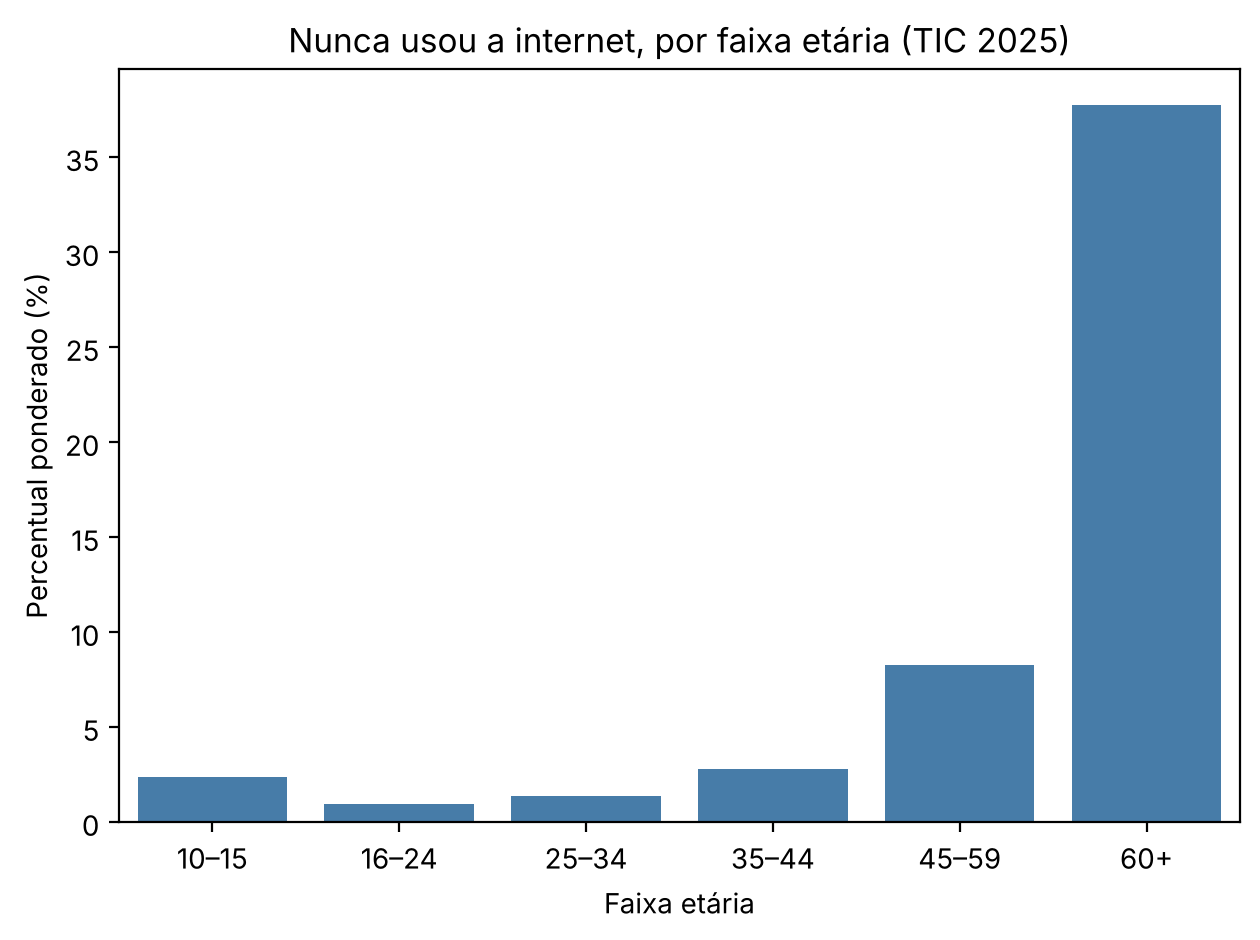

In [5]:
df["NUNCA_USOU"] = np.where(df["C1"].eq(0), 1,
                            np.where(df["C1"].eq(1), 0, np.nan))

p_nunca = proporcao_ponderada(df, "NUNCA_USOU")
print(f"Percentual ponderado que nunca utilizou a internet: {p_nunca:.2f}%")

faixas = {1:"10–15", 2:"16–24", 3:"25–34", 4:"35–44", 5:"45–59", 6:"60+"}
df["FAIXA_ETARIA_LABEL"] = df["FAIXA_ETARIA"].map(faixas)
idade = por_grupo(df, "FAIXA_ETARIA_LABEL", "NUNCA_USOU")
ordem = ["10–15", "16–24", "25–34", "35–44", "45–59", "60+"]
idade["FAIXA_ETARIA_LABEL"] = pd.Categorical(idade["FAIXA_ETARIA_LABEL"], categories=ordem, ordered=True)
idade = idade.sort_values("FAIXA_ETARIA_LABEL")
display(idade)

ax = sns.barplot(data=idade, x="FAIXA_ETARIA_LABEL", y="percentual", color="#377eb8")
ax.set(title="Nunca usou a internet, por faixa etária (TIC 2025)", xlabel="Faixa etária", ylabel="Percentual ponderado (%)")
plt.tight_layout()
plt.savefig(pasta_graficos / 'nunca_usou_por_idade.png', dpi=160)
plt.show()

## 6. Medidas estatísticas: a idade de quem nunca usou a internet

Os percentuais mostram **quantos** estão fora da internet. Agora usamos medidas de posição e de dispersão para descrever **quem** são essas pessoas, comparando a variável `IDADE` de quem nunca usou com a de quem já usou.

Como nas outras contas, cada pessoa entra com o seu peso da pesquisa:
- **Posição:** média, mediana, moda, quartis (Q1 e Q3) e percentis 5 e 95.
- **Dispersão:** variância, desvio-padrão, coeficiente de variação (desvio ÷ média), amplitude interquartil (Q3 − Q1), mínimo e máximo.

A mediana e os quartis ponderados são calculados ordenando as idades e acumulando os pesos até chegar a 25%, 50% e 75% do total.

In [6]:
def quantil_ponderado(valores, pesos, q):
    """Idade em que os pesos acumulados chegam à fração q do total."""
    ordem = np.argsort(valores)
    v, w = np.asarray(valores)[ordem], np.asarray(pesos)[ordem]
    acumulado = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(acumulado, q)])

def medidas_ponderadas(parte, coluna="IDADE", peso="PESO_NUM"):
    x = parte[coluna].to_numpy(dtype=float)
    w = parte[peso].to_numpy(dtype=float)
    media = np.average(x, weights=w)
    variancia = np.average((x - media) ** 2, weights=w)
    q1, mediana, q3 = (quantil_ponderado(x, w, q) for q in (0.25, 0.50, 0.75))
    return {
        "n_amostra": len(parte),
        "média": media,
        "mediana": mediana,
        "moda": parte.groupby(coluna)[peso].sum().idxmax(),
        "Q1": q1,
        "Q3": q3,
        "P5": quantil_ponderado(x, w, 0.05),
        "P95": quantil_ponderado(x, w, 0.95),
        "variância": variancia,
        "desvio-padrão": np.sqrt(variancia),
        "CV (%)": 100 * np.sqrt(variancia) / media,
        "IQR (Q3-Q1)": q3 - q1,
        "mínimo": x.min(),
        "máximo": x.max(),
    }

base_idade = df.loc[df["NUNCA_USOU"].isin([0, 1]) & df["PESO_NUM"].gt(0)].copy()
base_idade["GRUPO"] = base_idade["NUNCA_USOU"].map({1: "Nunca usou", 0: "Já usou"})

medidas = pd.DataFrame({
    "Nunca usou": medidas_ponderadas(base_idade[base_idade["GRUPO"].eq("Nunca usou")]),
    "Já usou": medidas_ponderadas(base_idade[base_idade["GRUPO"].eq("Já usou")]),
    "Todos": medidas_ponderadas(base_idade),
})
display(medidas.round(1))

# Conferência: sem peso, a média e a mediana do pandas ficam próximas das ponderadas.
print("Sem ponderação (conferência):")
display(base_idade.groupby("GRUPO")["IDADE"].agg(["mean", "median", "std"]).round(1))


,Nunca usou,Já usou,Todos
n_amostra,4582.0,19921.0,24503.0
média,64.9,37.7,40.4
mediana,68.0,36.0,39.0
moda,69.0,18.0,18.0
Q1,57.0,24.0,25.0
Q3,76.0,50.0,55.0
P5,30.0,12.0,13.0
P95,89.0,68.0,73.0
variância,281.1,297.4,362.4
desvio-padrão,16.8,17.2,19.0


Sem ponderação (conferência):


,mean,median,std
GRUPO,,,
Já usou,40.8,39.0,17.7
Nunca usou,63.5,67.0,16.1


### Distribuição da idade nos dois grupos

O histograma mostra, em cada grupo, a porcentagem de pessoas em cada faixa de 5 anos de idade (ponderada). O boxplot resume as mesmas distribuições: a caixa vai de Q1 a Q3, a linha do meio é a mediana, o losango é a média e as hastes vão do percentil 5 ao 95.

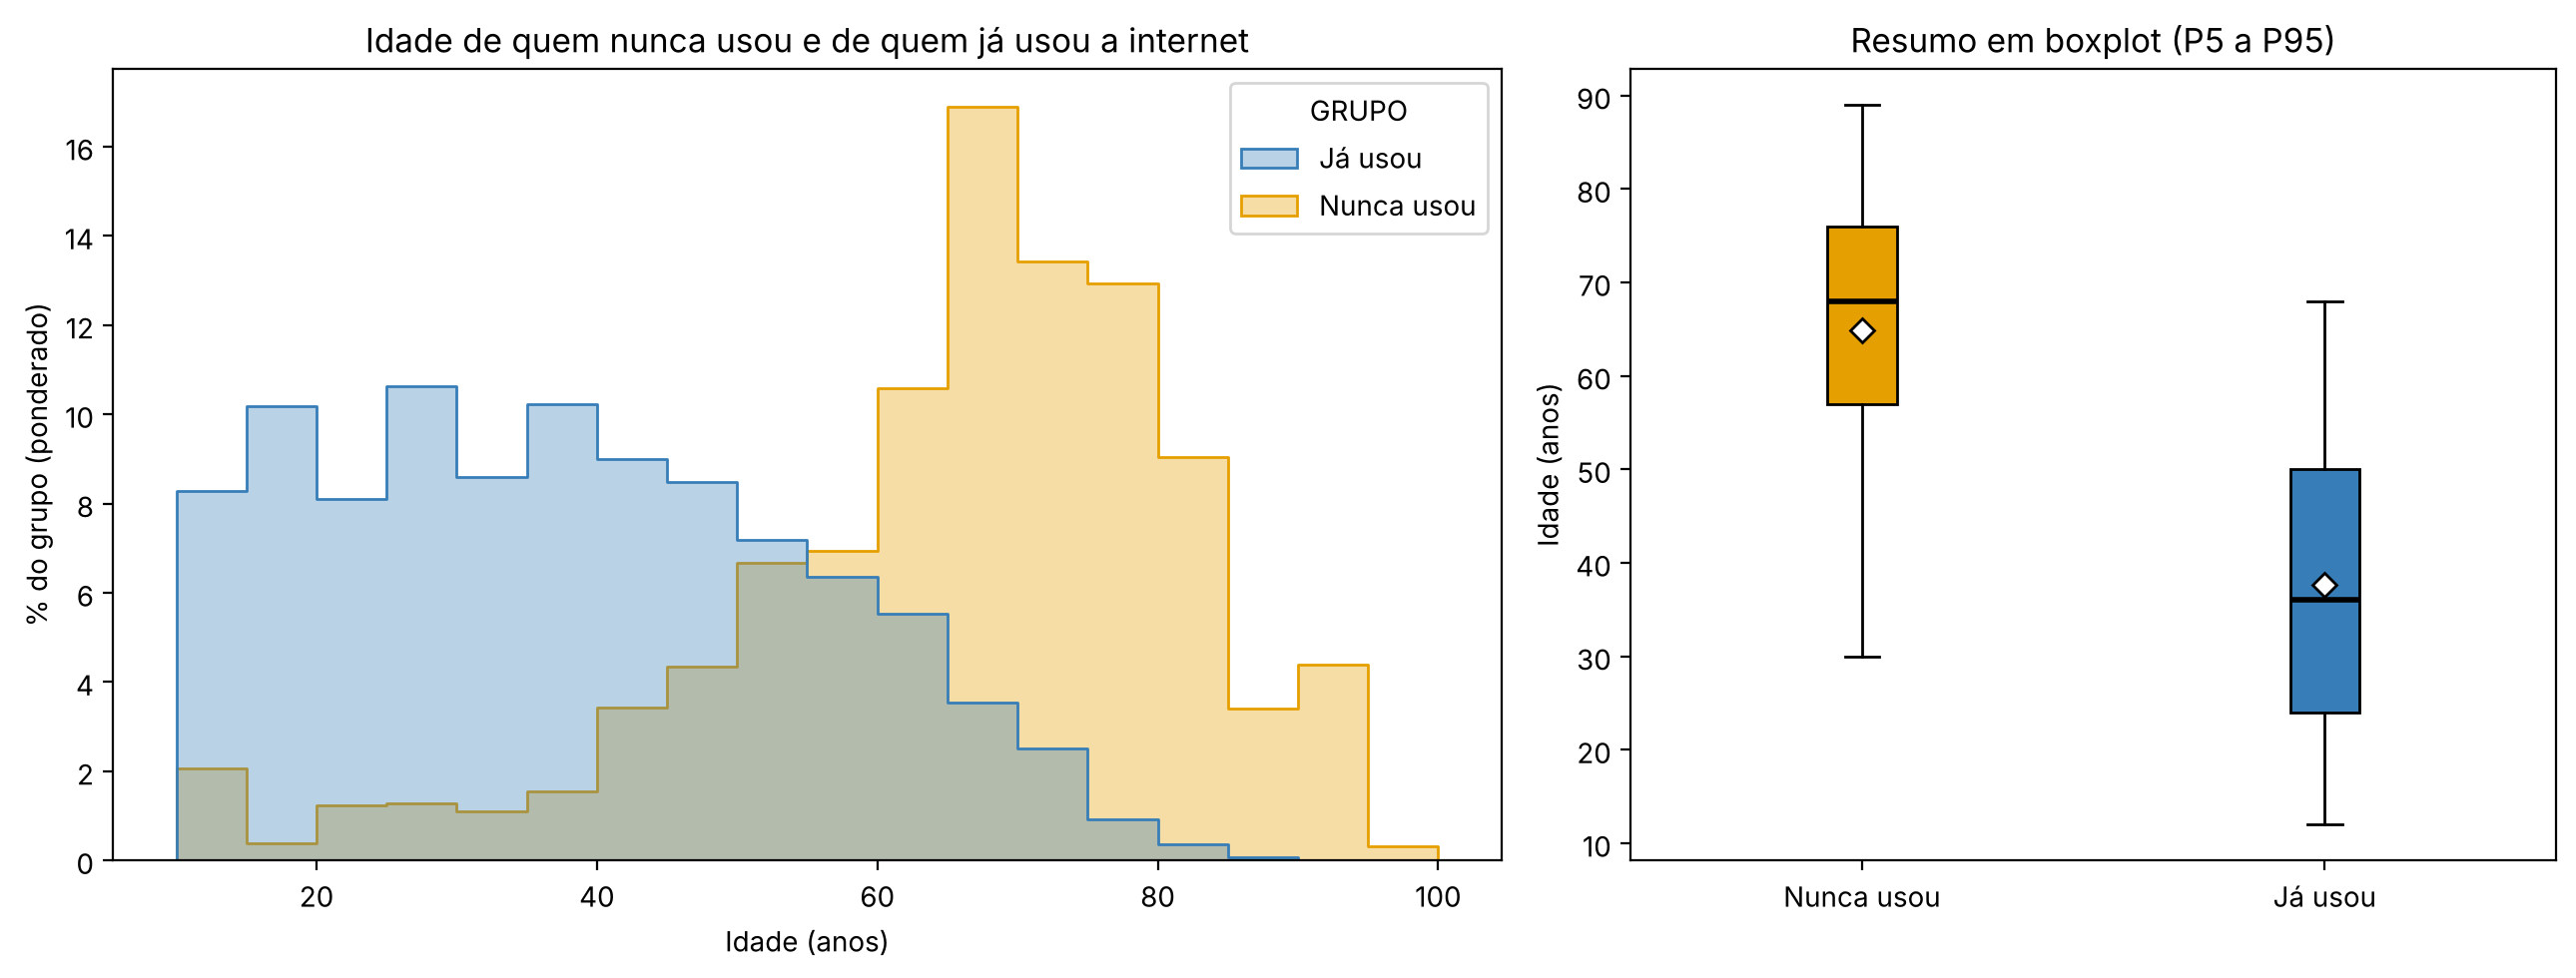

Mediana: 68 anos (nunca usou) x 36 anos (já usou).
Média: 64.9 x 37.7 anos; diferença de 27.2 anos.
75% de quem nunca usou tem 57 anos ou mais.


In [7]:
cores = {"Nunca usou": "#e69f00", "Já usou": "#377eb8"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 2]})

sns.histplot(data=base_idade, x="IDADE", hue="GRUPO", weights="PESO_NUM", stat="percent",
             common_norm=False, bins=range(10, 105, 5), element="step", fill=True,
             alpha=0.35, palette=cores, ax=ax1)
ax1.set(title="Idade de quem nunca usou e de quem já usou a internet",
        xlabel="Idade (anos)", ylabel="% do grupo (ponderado)")

caixas = []
for grupo in ["Nunca usou", "Já usou"]:
    m = medidas[grupo]
    caixas.append({"label": grupo, "med": m["mediana"], "q1": m["Q1"], "q3": m["Q3"],
                   "whislo": m["P5"], "whishi": m["P95"], "mean": m["média"], "fliers": []})
graf = ax2.bxp(caixas, showmeans=True, patch_artist=True,
               medianprops={"color": "black", "linewidth": 2},
               meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
for caixa, grupo in zip(graf["boxes"], ["Nunca usou", "Já usou"]):
    caixa.set_facecolor(cores[grupo])
ax2.set(title="Resumo em boxplot (P5 a P95)", ylabel="Idade (anos)")

plt.tight_layout()
plt.savefig(pasta_graficos / "idade_nunca_usou_vs_usou.png", dpi=160)
plt.show()

m_n, m_u = medidas["Nunca usou"], medidas["Já usou"]
print(f"Mediana: {m_n['mediana']:.0f} anos (nunca usou) x {m_u['mediana']:.0f} anos (já usou).")
print(f"Média: {m_n['média']:.1f} x {m_u['média']:.1f} anos; diferença de {m_n['média'] - m_u['média']:.1f} anos.")
print(f"75% de quem nunca usou tem {m_n['Q1']:.0f} anos ou mais.")


**O que as medidas mostram:** quem nunca usou a internet é, tipicamente, uma pessoa idosa. A mediana de idade desse grupo é **68 anos** (média de **64,9**), contra **36 anos** (média de **37,7**) entre quem já usou: uma diferença de cerca de **27 anos**. Três em cada quatro pessoas que nunca usaram têm **57 anos ou mais** (Q1), e a idade mais frequente no grupo é **69 anos**.

A dispersão também é diferente. O desvio-padrão é parecido nos dois grupos (cerca de 17 anos), mas o coeficiente de variação de quem nunca usou é bem menor (**25,8%** contra **45,8%**): em relação à média, esse grupo é mais homogêneo e concentrado nas idades mais altas. Isso confirma a resposta da pergunta 4 e reforça que a Lia deve ser pensada primeiro para pessoas com mais de 60 anos.

## 7. Por que algumas pessoas nunca usaram a internet?

Aqui analisamos a pergunta `C2_J`, que registra se **não saber usar** foi um dos motivos apontados por pessoas que nunca acessaram a internet.

Essa distinção é importante: o percentual que vamos calcular se refere **somente a quem nunca usou a internet e respondeu à pergunta**. Ele não representa a porcentagem de toda a população brasileira que tem dificuldade com tecnologia.


Entre quem nunca usou internet e respondeu C2_J, 81.89% citaram não saber usar.
Respondentes elegíveis com resposta válida: 4,568


,FAIXA_ETARIA_LABEL,percentual,n_amostra
0,10–15,58.798970,49
1,16–24,68.405350,79
2,25–34,54.709951,185
3,35–44,65.606975,283
4,45–59,73.718291,846
5,60+,87.040297,3126


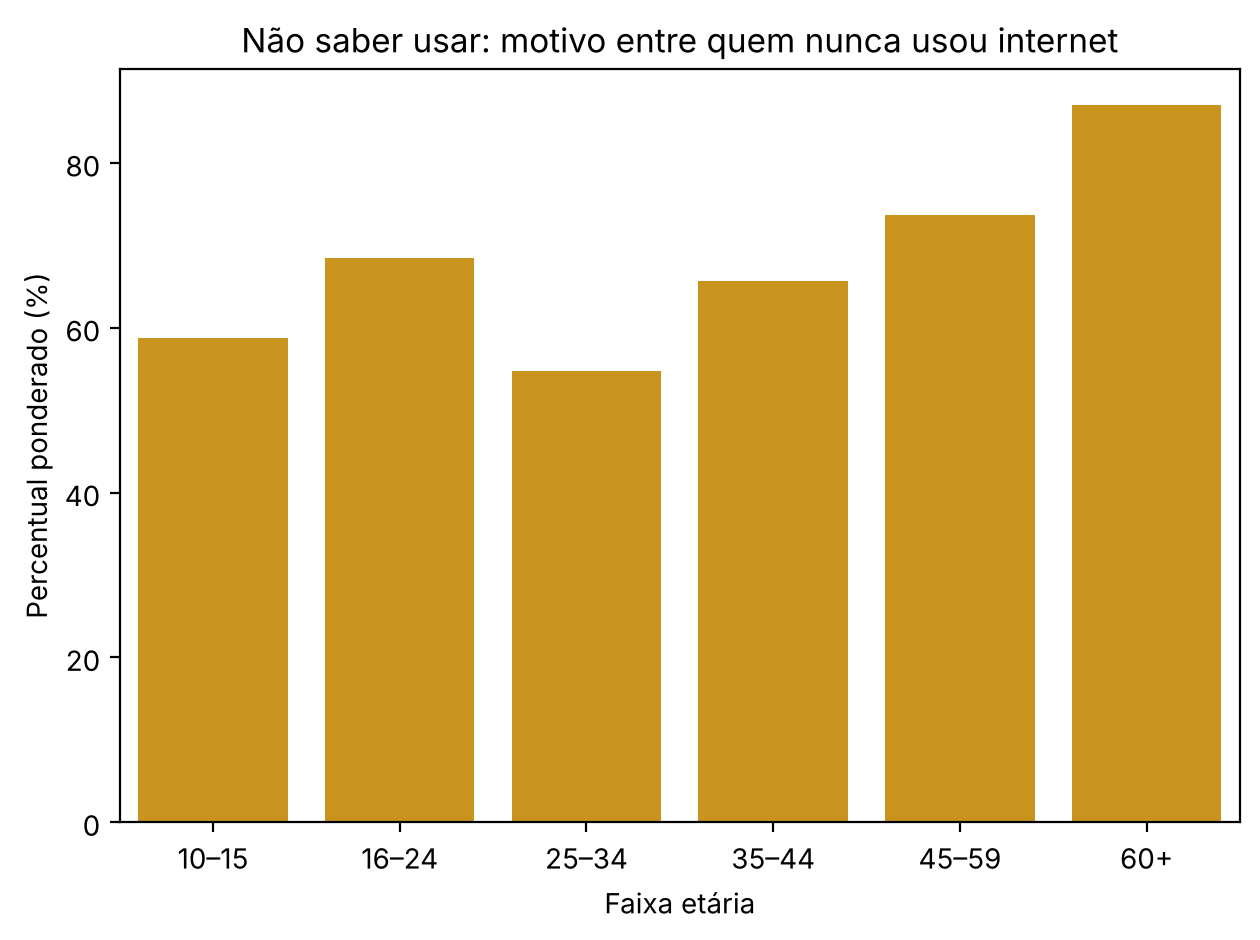

In [8]:
nao_usuarios = df.loc[df["C1"].eq(0)].copy()
validos_c2j = nao_usuarios.loc[nao_usuarios["C2_J"].isin([0, 1]) & nao_usuarios["PESO_NUM"].gt(0)]

p_nao_sabe = proporcao_ponderada(validos_c2j, "C2_J")
print(f"Entre quem nunca usou internet e respondeu C2_J, {p_nao_sabe:.2f}% citaram não saber usar.")
print(f"Respondentes elegíveis com resposta válida: {len(validos_c2j):,}")

por_idade = por_grupo(validos_c2j, "FAIXA_ETARIA_LABEL", "C2_J")
por_idade["FAIXA_ETARIA_LABEL"] = pd.Categorical(por_idade["FAIXA_ETARIA_LABEL"], categories=ordem, ordered=True)
por_idade = por_idade.sort_values("FAIXA_ETARIA_LABEL")
display(por_idade)

ax = sns.barplot(data=por_idade, x="FAIXA_ETARIA_LABEL", y="percentual", color="#e69f00")
ax.set(title="Não saber usar: motivo entre quem nunca usou internet", xlabel="Faixa etária", ylabel="Percentual ponderado (%)")
plt.tight_layout()
plt.savefig(pasta_graficos / 'nao_sabe_usar_por_idade.png', dpi=160)
plt.show()

## 8. O que muda conforme a escolaridade?

Para facilitar a leitura, vamos reunir os códigos do dicionário em cinco grupos: **Sem escola**, **Fundamental incompleto**, **Fundamental**, **Médio** e **Superior**. O agrupamento é uma escolha de apresentação deste trabalho, e não uma variável pronta da pesquisa.

Nos grupos “Médio” e “Superior” entram pessoas que cursaram ou concluíram essas etapas. A categoria “Fundamental incompleto” também reúne pré-escola, alfabetização e os primeiros anos da EJA. Isso evita mostrar vinte códigos diferentes no gráfico e mantém a comparação compreensível.

Continuamos utilizando os pesos da TIC e exibindo o número de respostas válidas de cada grupo.


/tmp/ipykernel_881/446088015.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ESCOLARIDADE_GRUPO'] = df['GRAU_INSTRUCAO_1'].map(grupo_escolar)


,ESCOLARIDADE_GRUPO,percentual,n_amostra
3,Sem escola,66.654448,1776
1,Fundamental incompleto,20.689626,9396
0,Fundamental,9.997445,1267
2,Médio,3.334188,9289
4,Superior,0.774430,2775


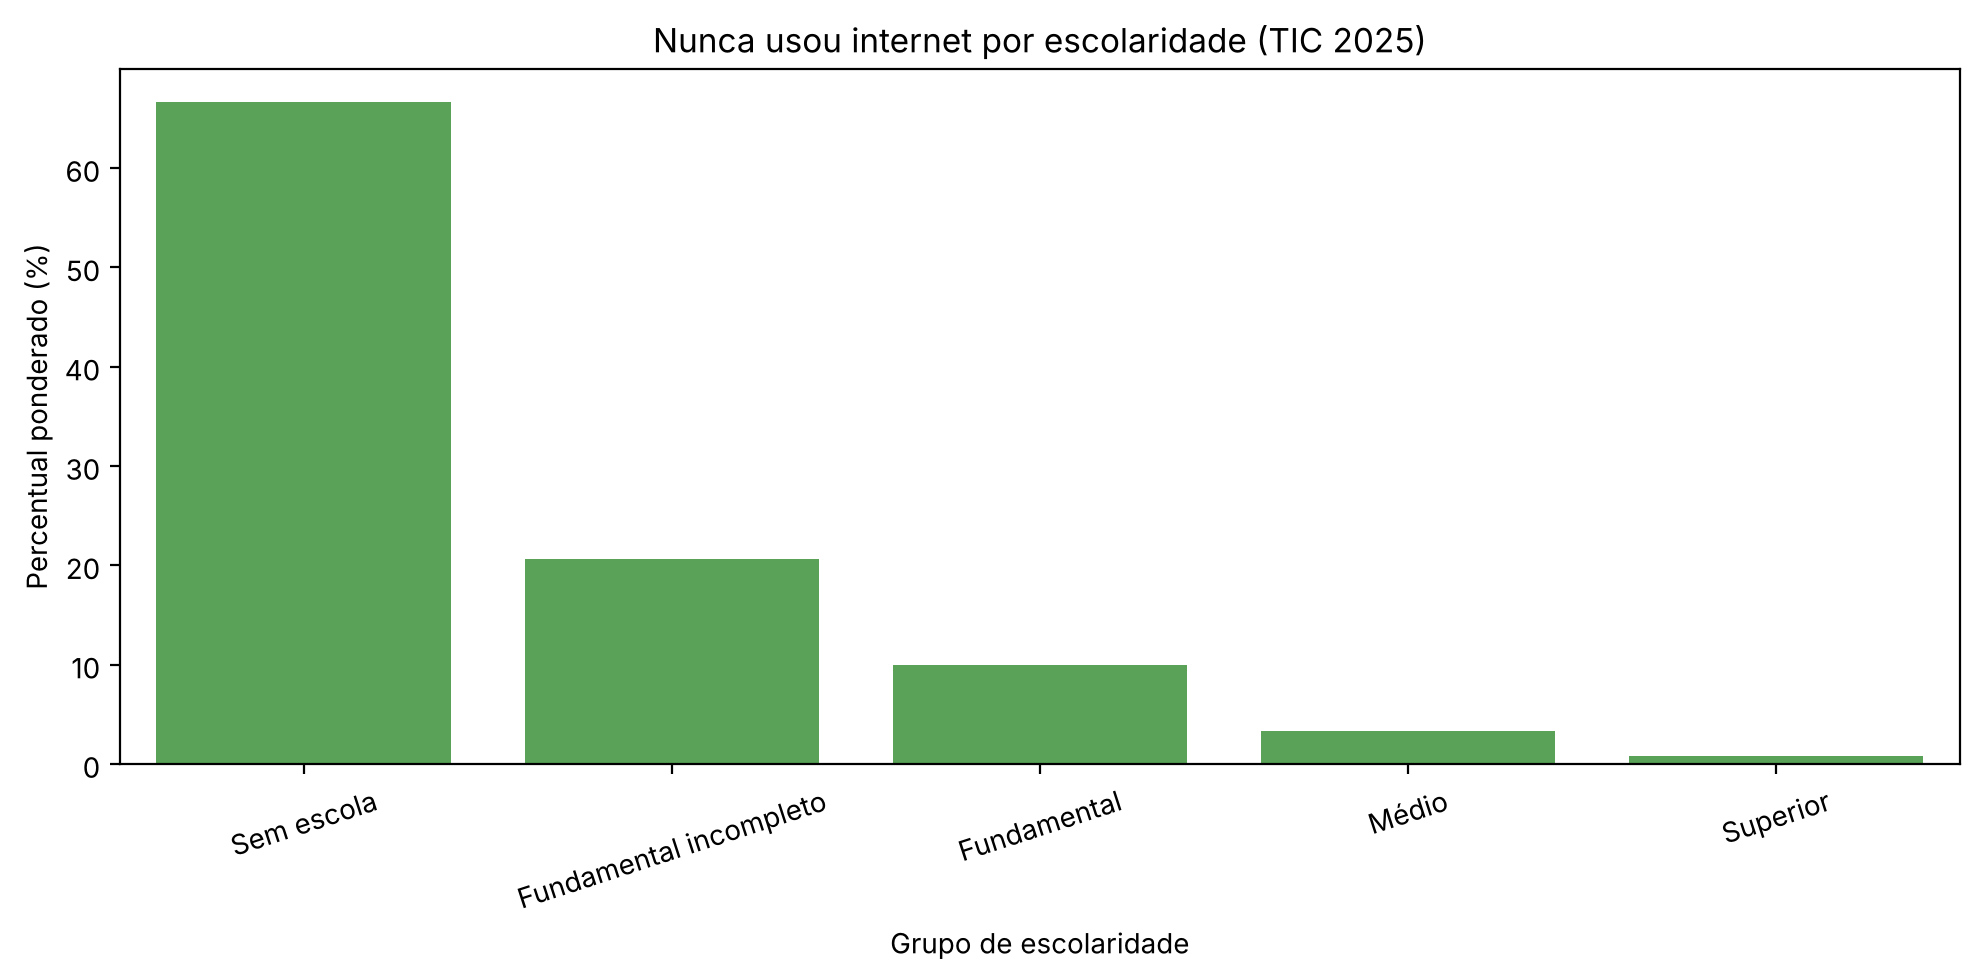

In [9]:
# Agrupamento dos códigos de escolaridade conforme o dicionário da TIC.
# 97/98 não entram: correspondem a respostas não informadas.
grupo_escolar = {
    1: 'Sem escola',
    2: 'Fundamental incompleto', 3: 'Fundamental incompleto',
    4: 'Fundamental incompleto', 5: 'Fundamental incompleto',
    6: 'Fundamental incompleto', 10: 'Fundamental incompleto',
    11: 'Fundamental incompleto', 12: 'Fundamental incompleto',
    7: 'Fundamental', 13: 'Fundamental',
    8: 'Médio', 9: 'Médio', 14: 'Médio', 15: 'Médio',
    16: 'Superior', 17: 'Superior', 18: 'Superior',
    19: 'Superior', 20: 'Superior'
}
ordem_escolar = ['Sem escola', 'Fundamental incompleto', 'Fundamental', 'Médio', 'Superior']
df['ESCOLARIDADE_GRUPO'] = df['GRAU_INSTRUCAO_1'].map(grupo_escolar)

esc = por_grupo(df, 'ESCOLARIDADE_GRUPO', 'NUNCA_USOU')
esc['ESCOLARIDADE_GRUPO'] = pd.Categorical(esc['ESCOLARIDADE_GRUPO'],
                                           categories=ordem_escolar, ordered=True)
esc = esc.sort_values('ESCOLARIDADE_GRUPO')
display(esc)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=esc, x='ESCOLARIDADE_GRUPO', y='percentual', color='#4daf4a', ax=ax)
ax.set(title='Nunca usou internet por escolaridade (TIC 2025)',
       xlabel='Grupo de escolaridade', ylabel='Percentual ponderado (%)')
ax.tick_params(axis='x', rotation=18)
plt.tight_layout()
plt.savefig(pasta_graficos / 'nunca_usou_por_escolaridade.png', dpi=160)
plt.show()


## 9. Outros motivos para não usar

Vamos comparar as respostas sobre interesse, custo, segurança, acesso e outros motivos. No lugar dos códigos `C2_I` e `C2_J`, o gráfico mostrará o significado de cada pergunta, conforme o dicionário.

Uma mesma pessoa podia indicar **mais de um motivo**, então a soma dos percentuais pode ultrapassar 100%. Em cada motivo são consideradas apenas as respostas 0 e 1 com peso válido; também registramos a quantidade de respostas usadas no cálculo.


,variavel,motivo,percentual,n_amostra
0,C2_J,Não sabe usar,81.893338,4568
1,C2_I,Falta de interesse,63.972259,4534
2,C2_G,Evitar conteúdo perigoso,46.575078,4513
3,C2_F,Segurança/privacidade,44.780580,4522
4,C2_E,Muito caro,33.161931,4466
5,C2_D,Não tem onde acessar,27.265795,4521
6,C2_OUTRO,Outro motivo,2.349661,4582


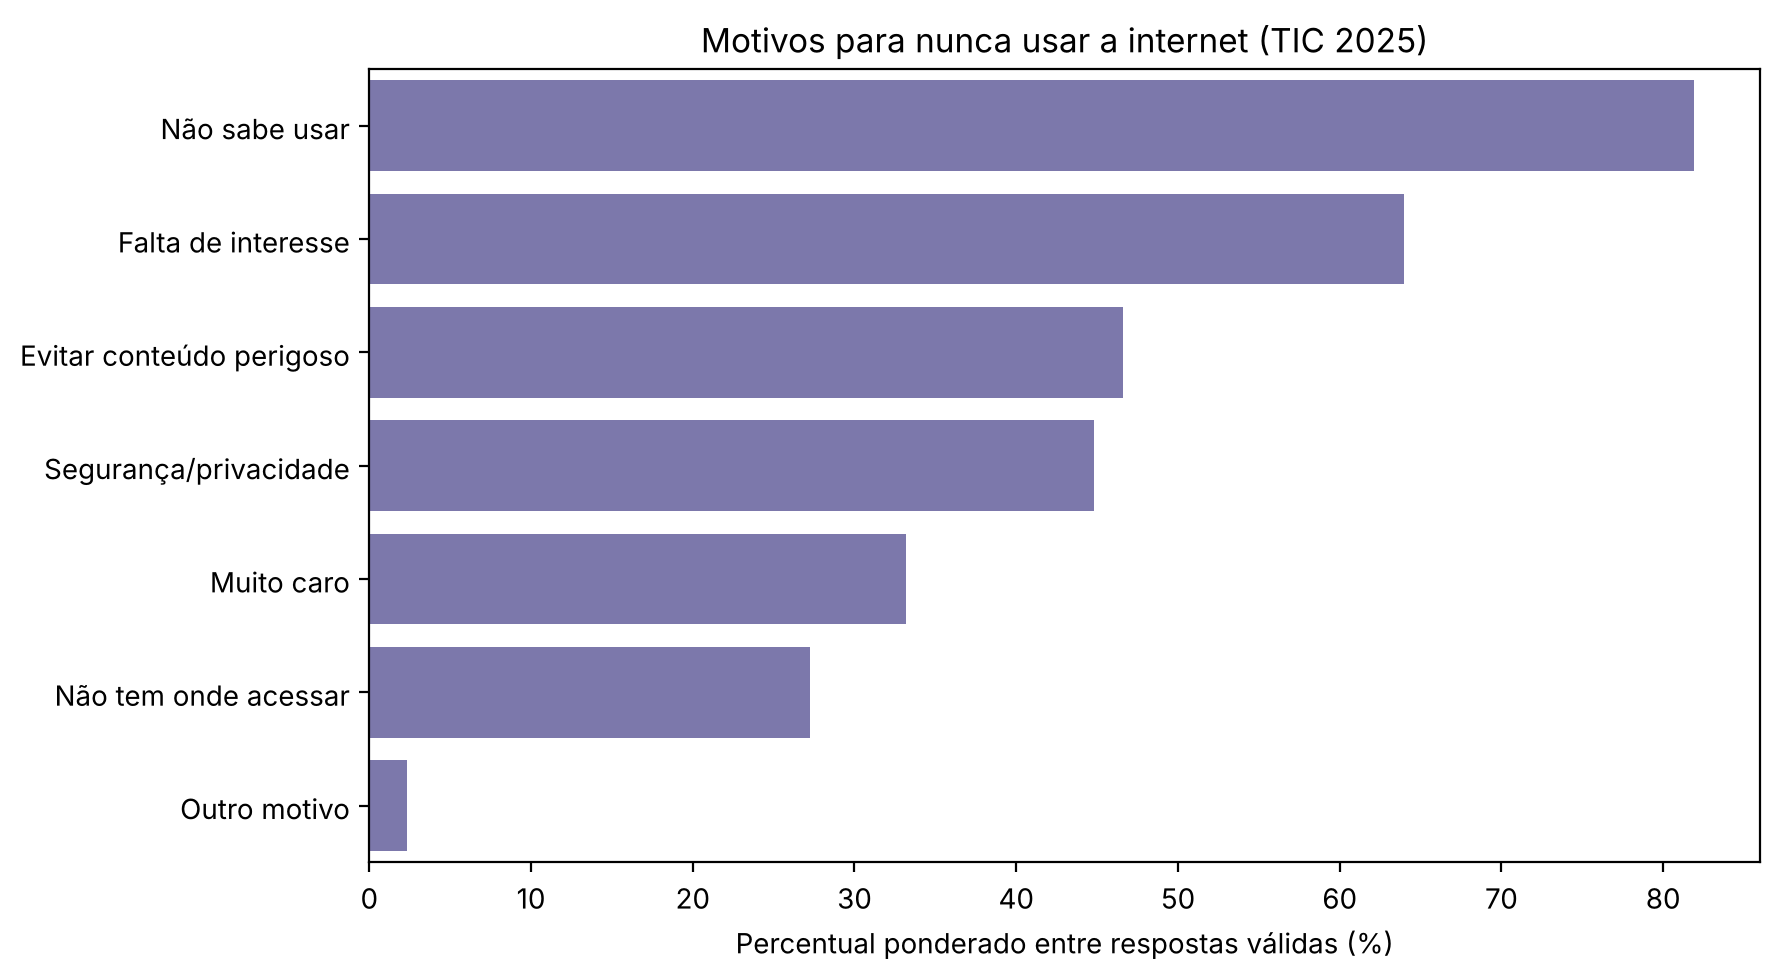

In [10]:
# Rótulos do dicionário de variáveis, com nomes mais fáceis de ler.
nomes_motivos = {
    'C2_J': 'Não sabe usar',
    'C2_I': 'Falta de interesse',
    'C2_G': 'Evitar conteúdo perigoso',
    'C2_F': 'Segurança/privacidade',
    'C2_E': 'Muito caro',
    'C2_D': 'Não tem onde acessar',
    'C2_OUTRO': 'Outro motivo'
}
res = []
for codigo, nome in nomes_motivos.items():
    if codigo in nao_usuarios.columns:
        respostas_validas = nao_usuarios[
            nao_usuarios[codigo].isin([0, 1]) & nao_usuarios['PESO_NUM'].gt(0)
        ]
        res.append({'variavel': codigo, 'motivo': nome,
                    'percentual': proporcao_ponderada(respostas_validas, codigo),
                    'n_amostra': len(respostas_validas)})

bar = pd.DataFrame(res).sort_values('percentual', ascending=False)
display(bar)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=bar, y='motivo', x='percentual', color='#7570b3', ax=ax)
ax.set(title='Motivos para nunca usar a internet (TIC 2025)',
       xlabel='Percentual ponderado entre respostas válidas (%)', ylabel='')
plt.tight_layout()
plt.savefig(pasta_graficos / 'motivos_para_nao_usar.png', dpi=160)
plt.show()


## 10. Guardando os resultados

Para facilitar a elaboração do relatório, salvamos quatro tabelas resumidas na pasta `datasets/processed`. Elas trazem somente os indicadores agregados: nunca utilizou por idade, dificuldade de uso por idade, nunca utilizou por escolaridade e lista de barreiras.

Os microdados originais continuam intactos na pasta `datasets/raw`.


In [11]:
saida = RAIZ / "datasets" / "processed"
saida.mkdir(parents=True, exist_ok=True)
idade.to_csv(saida / "tic2025_nunca_usou_por_idade.csv", index=False, encoding="utf-8-sig")
por_idade.to_csv(saida / "tic2025_nao_sabe_usar_por_idade.csv", index=False, encoding="utf-8-sig")
esc.to_csv(saida / "tic2025_nunca_usou_por_escolaridade.csv", index=False, encoding="utf-8-sig")
bar.to_csv(saida / "tic2025_barreiras_uso_internet.csv", index=False, encoding="utf-8-sig")
print("Tabelas salvas em:", saida)
print(f"\nSÍNTESE DESCRITIVA:\n- Nunca usou internet: {p_nunca:.1f}% (ponderado).")
print(f"- Entre quem nunca usou e respondeu à pergunta, não saber usar foi citado por {p_nao_sabe:.1f}%.")

Tabelas salvas em: /content/GS_LIA_DataScience/datasets/processed

SÍNTESE DESCRITIVA:
- Nunca usou internet: 10.0% (ponderado).
- Entre quem nunca usou e respondeu à pergunta, não saber usar foi citado por 81.9%.


## 11. Principais resultados e relação com a AuxiLia

Na TIC Domicílios 2025, **37,8% das pessoas de 60 anos ou mais nunca utilizaram a internet**, um percentual bem superior ao observado nas faixas mais jovens. Entre as pessoas que nunca usaram a internet e responderam à pergunta sobre o motivo, **81,9% mencionaram não saber usar**; no grupo de 60 anos ou mais, a proporção chegou a **87,0%**. As medidas de idade mostram o mesmo quadro: a **mediana de quem nunca usou é 68 anos**, contra 36 anos de quem já usou, e 75% desse grupo tem 57 anos ou mais. Esses resultados ajudam a justificar testes da AuxiLia com pessoas idosas e uma interface que utilize voz, explicações breves e orientações passo a passo.

Os percentuais são **ponderados pelos pesos da pesquisa**. O indicador sobre “não saber usar” se refere apenas a quem **nunca utilizou** a internet e respondeu validamente à pergunta, e não à população brasileira inteira. Os dados apoiam a escolha do público a pesquisar, mas a eficácia do aplicativo ainda precisa ser testada.

**Fonte:** CGI.br/Cetic.br — TIC Domicílios 2025, microdados de indivíduos e dicionário de variáveis. https://cetic.br/pt/arquivos/domicilios/2025/individuos/
